In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\Aliyan\Downloads\student_tea_snacks.csv")
df.info()
df.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   student_id    100 non-null    str  
 1   gender        100 non-null    str  
 2   age_group     100 non-null    str  
 3   prefers_tea   100 non-null    str  
 4   tea_type      77 non-null     str  
 5   snack_choice  100 non-null    str  
 6   cups_per_day  100 non-null    int64
dtypes: int64(1), str(6)
memory usage: 8.3 KB


,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4


Q1 - Tea Type Breakdown:
 tea_type
Green          29
Doodh Patti    25
Black          23
Name: count, dtype: int64

Most preferred tea type: Green (29 students)

Q2 - Average number of cups per gender:
 gender
Female    2.6
Male      3.0
Name: cups_per_day, dtype: float64


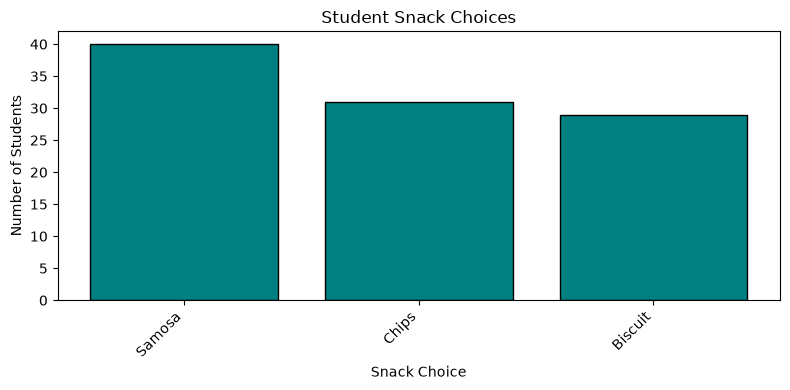


Q4 - Tea preference by age group:



tea_type,Black,Doodh Patti,Green
age_group,,,
18-20,9,11,13
21-23,9,6,5
24-26,5,8,11



Q5 - Number of students who don't drink tea: 65


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 0. LOAD DATA & DETECT COLUMNS
# ==========================================
df = pd.read_csv(r"C:\Users\Aliyan\Downloads\student_tea_snacks.csv")

def find_col(keywords):
    for col in df.columns:
        if any(k in col.lower() for k in keywords):
            return col
    raise KeyError(f"Column matching {keywords} not found in {df.columns.tolist()}")

# Separate the Yes/No tea drinker column from the actual tea flavor/type column
tea_cols = [c for c in df.columns if 'tea' in c.lower()]
tea_col = None
drinks_tea_col = None

for c in tea_cols:
    vals = set(df[c].dropna().astype(str).str.strip().str.lower().unique())
    if vals.issubset({'yes', 'no', 'y', 'n', 'true', 'false', '1', '0'}):
        drinks_tea_col = c
    elif tea_col is None:
        tea_col = c

if tea_col is None:
    tea_col = tea_cols[0]

gender_col = find_col(['gender', 'sex'])
cups_col = find_col(['cup'])
snack_col = find_col(['snack'])
age_col = find_col(['age'])


# Q1: What is the most preferred tea type?

tea_counts = df[tea_col].value_counts()
exclude_non_tea = {'none', 'no tea', 'no', 'yes', "don't drink", 'do not drink', 'nan', ''}
actual_teas = tea_counts[~tea_counts.index.astype(str).str.strip().str.lower().isin(exclude_non_tea)]

print("Q1 - Tea Type Breakdown:\n", actual_teas)
print(f"\nMost preferred tea type: {actual_teas.idxmax()} ({actual_teas.max()} students)")


# Q2: What is the average number of cups per gender?

df[cups_col] = pd.to_numeric(df[cups_col], errors='coerce')
avg_cups = df.groupby(gender_col)[cups_col].mean().round(2)
print("\nQ2 - Average number of cups per gender:\n", avg_cups)

# Q3: Make a bar chart of snack choices
snack_counts = df[snack_col].value_counts()

plt.figure(figsize=(8, 4))
plt.bar(snack_counts.index, snack_counts.values, color='teal', edgecolor='black')
plt.xlabel('Snack Choice')
plt.ylabel('Number of Students')
plt.title('Student Snack Choices')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# Q4: Compare tea preference by age group.

tea_by_age = pd.crosstab(df[age_col], df[tea_col])
print("\nQ4 - Tea preference by age group:\n")
display(tea_by_age)


# Q5: Count the number of students who don't drink tea.
no_tea_mask = (
    df[tea_col].isna() |
    df[tea_col].astype(str).str.strip().str.lower().isin({'none', 'no tea', 'no', "don't drink", 'do not drink', 'nan', ''}) |
    (df[cups_col] == 0)
)

if drinks_tea_col is not None:
    no_tea_mask = no_tea_mask | df[drinks_tea_col].astype(str).str.strip().str.lower().isin({'no', 'n', 'false', '0'})

print("\nQ5 - Number of students who don't drink tea:", no_tea_mask.sum())